In [1]:
import pandas as pd

df = pd.read_csv("UsArrests.csv", index_col=0)

df.head()

,Murder,Assault,UrbanPop,Rape
City,,,,
Alabama,13.2,236,58,21.2
Alaska,10.0,263,48,44.5
Arizona,8.1,294,80,31.0
Arkansas,8.8,190,50,19.5
California,9.0,276,91,40.6


In [2]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
Index: 50 entries, Alabama to Wyoming
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Murder    50 non-null     float64
 1   Assault   50 non-null     int64  
 2   UrbanPop  50 non-null     int64  
 3   Rape      50 non-null     float64
dtypes: float64(2), int64(2)
memory usage: 2.0+ KB


,Murder,Assault,UrbanPop,Rape
count,50.00000,50.000000,50.000000,50.000000
mean,7.78800,170.760000,65.540000,21.232000
std,4.35551,83.337661,14.474763,9.366385
min,0.80000,45.000000,32.000000,7.300000
25%,4.07500,109.000000,54.500000,15.075000
50%,7.25000,159.000000,66.000000,20.100000
75%,11.25000,249.000000,77.750000,26.175000
max,17.40000,337.000000,91.000000,46.000000


In [3]:
df.var()

Murder        18.970465
Assault     6945.165714
UrbanPop     209.518776
Rape          87.729159
dtype: float64

The variables are measured on different scales (e.g., assault rates vs urban population percentage). Standardisation is required before PCA so that variables contribute equally.

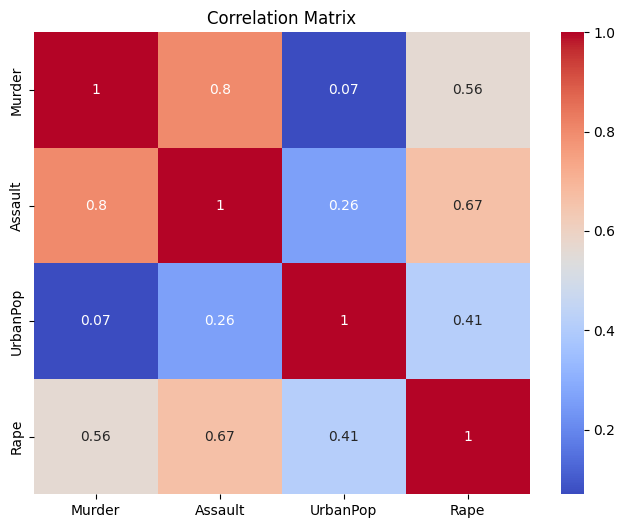

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

sns.heatmap(df.corr(), annot=True, cmap="coolwarm")

plt.title("Correlation Matrix")
plt.show()

Murder and Assault are strongly positively correlated

UrbanPop has weaker correlation with violent crime variables

Rape moderately correlates with assault

This suggests crime variables move together across states.

In [5]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaled_data = scaler.fit_transform(df)

In [6]:
from sklearn.decomposition import PCA

pca = PCA()

X_pca = pca.fit_transform(scaled_data)

In [7]:
pca.explained_variance_ratio_

array([0.62006039, 0.24744129, 0.0891408 , 0.04335752])

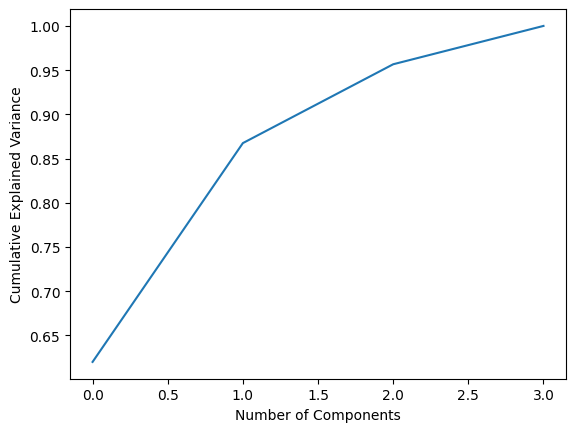

In [8]:
import numpy as np

plt.plot(np.cumsum(pca.explained_variance_ratio_))

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")

plt.show()

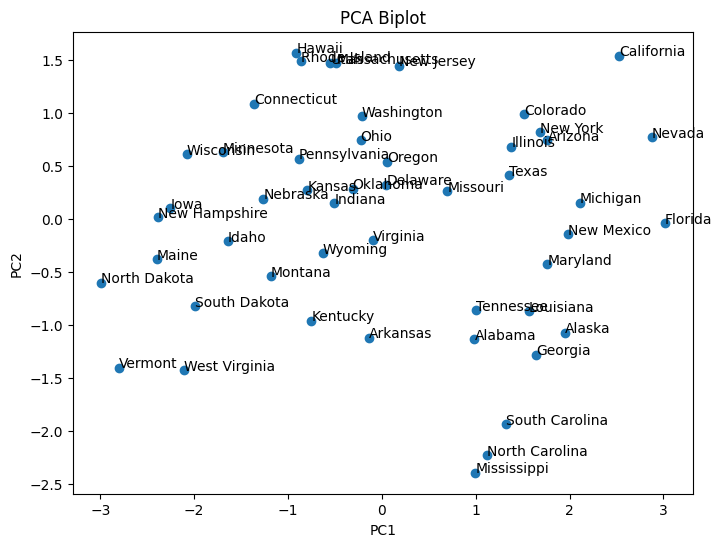

In [9]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(scaled_data)

plt.figure(figsize=(8,6))

plt.scatter(X_pca[:,0], X_pca[:,1])

for i, state in enumerate(df.index):
    plt.text(X_pca[i,0], X_pca[i,1], state)

plt.xlabel("PC1")
plt.ylabel("PC2")

plt.title("PCA Biplot")

plt.show()

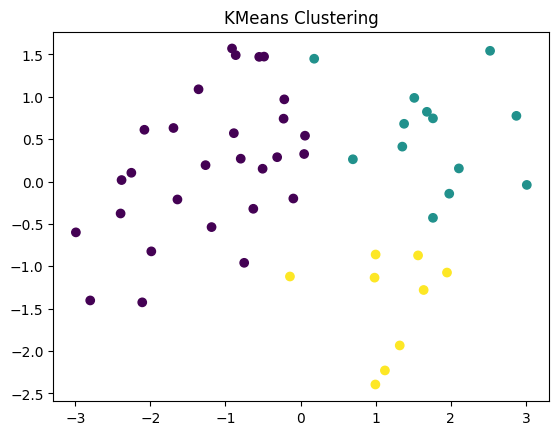

In [10]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42)

labels_kmeans = kmeans.fit_predict(X_pca)

plt.scatter(X_pca[:,0], X_pca[:,1], c=labels_kmeans)

plt.title("KMeans Clustering")

plt.show()

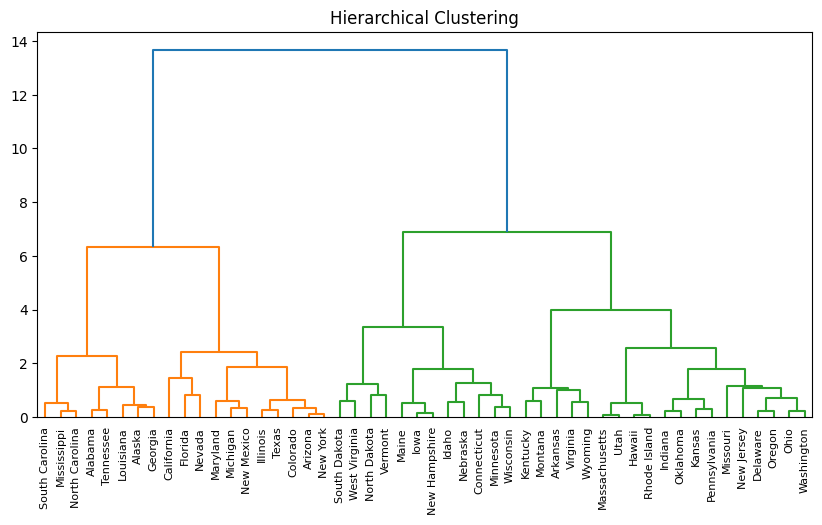

In [11]:
from scipy.cluster.hierarchy import linkage, dendrogram

Z = linkage(X_pca, method="ward")

plt.figure(figsize=(10,5))

dendrogram(Z, labels=df.index)

plt.title("Hierarchical Clustering")

plt.show()

luster 1 – High crime states
States with high murder, assault, and rape rates. These states appear strongly on the positive side of PC1.

Cluster 2 – Moderate crime states
States with average crime rates and mixed urbanisation levels.

Cluster 3 – Low crime states
States with relatively low violent crime rates.